In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'  

os.makedirs("Results", exist_ok=True)
from scipy.interpolate import CubicSpline as CS
import torch
import numpy as np
import torch.nn as nn
from torch.autograd import grad
import matplotlib.pyplot as plt
from timeit import default_timer
import scipy.signal
import scipy
import pickle
from scipy.interpolate import PchipInterpolator as PI
# GPU 
device = 'cuda' if torch.cuda.is_available() else 'cpu'

torch.set_default_dtype(torch.float32)

# radom seed
torch.manual_seed(42)
np.random.seed(42)
if device == 'cuda':
    torch.cuda.manual_seed_all(42)

In [2]:
a=7 #limit
batch_size_pde=2001 #discretisation number
x_intp=np.linspace(-a,a,batch_size_pde)
#wakefield models
def bbr(q,om):
    value=-np.exp(om*q/2)*(np.cos(np.sqrt(3)/2*om*q)+1/np.sqrt(3)*np.sin(np.sqrt(3)/2*om*q))
    return value
def csrS(q):
    return -4*np.pi*q**(-1/3)*3**(-1/3)
def csr(q):
    return 4*np.pi*q**(-4/3)*3**(-4/3)

In [26]:
# distributions and currents
files = [
    (r"D:\dis_pp\bbr_7_1000_0.5_1",  1),
    (r"D:\dis_pp\bbr_7_1000_0.5_3",  3),
    (r"D:\dis_pp\bbr_7_1000_0.5_5",  5),
    (r"D:\dis_pp\bbr_7_1000_0.5_7", 7),
]

data0 = pickle.load(open(files[0][0], 'rb'))
xtt = np.linspace(-7, 7, np.shape(data0)[0])

# the function of disributions λ(q)
func_CS_list = [
    CS(xtt, pickle.load(open(path, 'rb')).T[0])
    for path, _ in files
]

# currents
I_norm = np.array([n for _, n in files])

# input vector
u_given   = np.hstack([np.atleast_2d(f(x_intp)).T           for f in func_CS_list])
u_x_given = np.hstack([np.atleast_2d(f.derivative()(x_intp)).T for f in func_CS_list])

u_given   = torch.from_numpy(u_given).float().to(device)
u_x_given = torch.from_numpy(u_x_given).float().to(device)

In [27]:
class PINN(nn.Module):
    def __init__(self, input_dim=1, output_dim=1, hidden_dim=50, num_hidden=3):
        """
        initialization of PINN

        input_dim: 1 for default
        output_dim: 1 for default
        hidden_dim: number of neurons
        num_hidden: number of hidden layers
        
        """
        super(PINN, self).__init__()

        self.main_layers = nn.ModuleList([nn.Linear(input_dim, hidden_dim*2)])
        for _ in range(num_hidden - 1):
            self.main_layers.append(nn.Linear(hidden_dim, hidden_dim*2))
        self.main_layers.append(nn.Linear(hidden_dim, output_dim))
        
        
        self.local_layers = nn.ModuleList([nn.Linear(input_dim, hidden_dim*2)])
        for _ in range(num_hidden - 1):
            self.local_layers.append(nn.Linear(hidden_dim, hidden_dim*2))
        self.local_layers.append(nn.Linear(hidden_dim, output_dim))
        
       
        self.decay_rates = nn.Parameter(torch.tensor([1.0]))
        self.transition_rates = nn.Parameter(torch.tensor([2.0]))
        self.transition_point = nn.Parameter(torch.tensor([3.0]))
        
        
       
    
    def forward(self, x):
        transition = torch.sigmoid(-(x + self.transition_point) * self.transition_rates)
        x_in = x / a

        out = x_in
        for layer in self.main_layers[:-1]:
            h = layer(out)
            gate, value = h.chunk(2, dim=1)
            out = torch.tanh(gate) * value
        out = self.main_layers[-1](out)
        
        out_corr = x_in
        for layer in self.local_layers[:-1]:
            h = layer(out_corr)
            gate, value = h.chunk(2, dim=1)
            out_corr = torch.tanh(gate) * value
        out_corr = self.local_layers[-1](out_corr)
        
        
        
        decay_rate = torch.abs(self.decay_rates)  
        exp_part = torch.exp(-torch.abs(x) * decay_rate)
        
        
        output = out* (1 -transition) + exp_part * transition*out_corr
        mask=(x<=0).to(x.dtype)
        return output*(mask)
    
    
    def losses(self, x):
        x_combined = x['pde']
        wake_pred=self.forward(x_combined)
        # shape: [batch_size, channels, length]
        # shape: u_pred [N, 1] to [1, 1, N]
        total_loss=0
        dx=2*a/(batch_size_pde-1)
        for i in range(0,4):
            u_for_conv = u_given[:,i].reshape(-1,1).T.unsqueeze(0)  # [1, 1, N]
            
            wake_kernel=wake_pred.flip(0).view(1, 1, -1) 
            
            convolve_result = torch.nn.functional.conv1d(
                u_for_conv,wake_kernel,
                padding='same'  # 保持输出长度相同
            )
            
           
            convolve_tensor = convolve_result.squeeze().unsqueeze(1)  # [N, 1]
           
            
            # 计算残差
            residual = u_x_given[:,i].reshape(-1,1) + (x_combined + I_norm[i] * convolve_tensor*dx) * u_given[:,i].reshape(-1,1)
        
            loss_pde = torch.mean(residual**2)
       
            
            total_loss = loss_pde+total_loss
       
        
        
    
       
        if not hasattr(self, 'history'):
            self.history = {
                'loss_pde': []
            }


        self.history['loss_pde'].append(total_loss.item())
        
        return total_loss



def get_data(batch_size_pde):
    """
    batch_size_pde: number of PDE points
    """

    x = np.linspace(-a, a, batch_size_pde)
    
    

    x_pde = x
    x_pde_flat = x_pde.flatten()[:, None] 
    
    

    x_train = {'pde': x_pde_flat}
    

    for key in x_train.keys():
        x_train[key] = torch.from_numpy(x_train[key]).float().to(device)
    
    x_test = x.flatten()[:, None]
    
    
    x_test = torch.from_numpy(x_test).float().to(device)
    
    return x_test, x_train


In [28]:
def train_pinn_adam(pinn, x_train, epochs=5000, lr=1e-3):
    """
    pinn: PINN instance
    x_train: space coordinate
    epochs: 
    lr: learning rates
    """
    special_params = ['decay_rates','transition_point','transition_rates']

    optimizer = torch.optim.Adam([
        {'params': [p for n, p in pinn.named_parameters() 
                    if not any(sp in n for sp in special_params)], 
         'lr': lr},                    
        {'params': [pinn.decay_rates], 'lr': lr},
        {'params': [pinn.transition_point], 'lr': lr},
        {'params': [pinn.transition_rates], 'lr': lr},# 
    ])
    print("start Adam trainning...")
    for epoch in range(epochs):
        optimizer.zero_grad()
        loss_pde = pinn.losses(x_train)
        loss_pde.backward(retain_graph=True)
        optimizer.step()
        if (epoch+1) % 1000 == 0:
            print(f"epoch {epoch+1}: PDE loss = {loss_pde.item():.6e}")
        
    print("Adam training done")

def train_pinn_lbfgs(pinn, x_train, max_iter=500, lr=0.01, tolerance_grad=1e-10, tolerance_change=1e-10):
    """
    pinn: PINN instance
    x_train: space coordinate
    lr: learning rates
    """
    
    optimizer = torch.optim.LBFGS(
        pinn.parameters(),
        lr=lr,
        max_iter=max_iter,
        tolerance_grad=tolerance_grad,
        tolerance_change=tolerance_change,
        line_search_fn="strong_wolfe",
        history_size=100
    )
    
    def closure():
        optimizer.zero_grad()
        loss_pde = pinn.losses(x_train)
        loss_pde.backward(retain_graph=True)
        return loss_pde
    
    print("start L-BFGS trainning...")
    optimizer.step(closure)
    print("L-BFGS training done")


def plot_loss_history(pinn):
    """
    pinn: PINN instance
    """
    # check if history is recorded
    if not hasattr(pinn, 'history'):
        print("No loss history available.")
        return

    epochs = range(len(pinn.history['loss_pde']))

    plt.figure(figsize=(10, 6))
    plt.semilogy(epochs, pinn.history['loss_pde'], label='PDE Residual Loss')
    plt.title('Loss During Training')
    plt.xlabel('Epochs')
    plt.ylabel('Loss (Log Scale)')
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

start Adam trainning...
epoch 1000: PDE loss = 7.346365e-06
epoch 2000: PDE loss = 1.142372e-06
epoch 3000: PDE loss = 2.955562e-07
epoch 4000: PDE loss = 1.274869e-07
epoch 5000: PDE loss = 1.869999e-07
epoch 6000: PDE loss = 8.138268e-06
epoch 7000: PDE loss = 8.172081e-08
epoch 8000: PDE loss = 1.073754e-07
Adam training done
start L-BFGS trainning...
L-BFGS training done
time cost：134.35587850000047 s


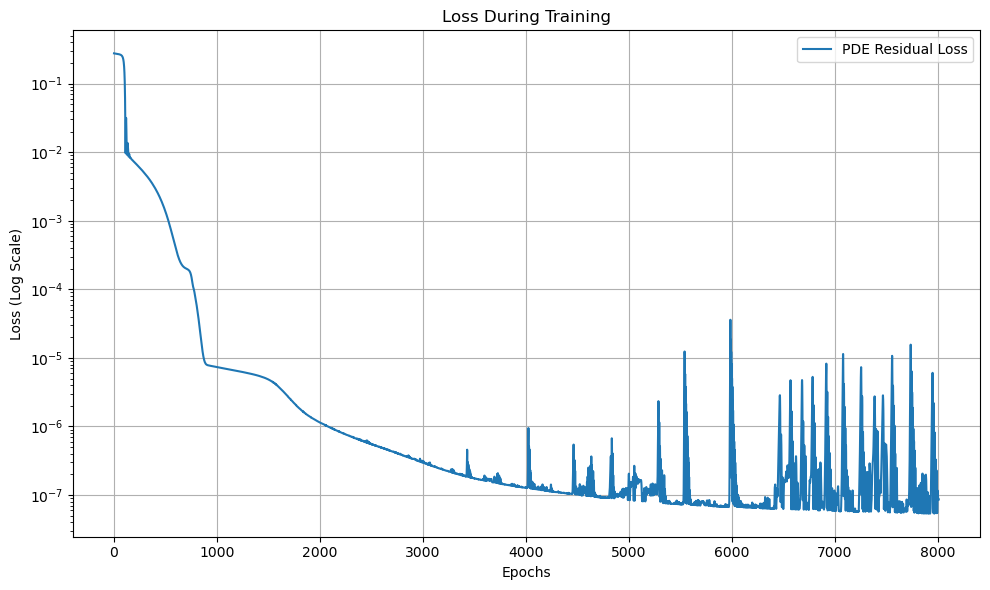

In [29]:
x_test,x_train= get_data(batch_size_pde)

model = PINN(
    input_dim=1, 
    output_dim=1, 
    hidden_dim=100, 
    num_hidden=4
).to(device)

t1 = default_timer()

train_pinn_adam(model, x_train, epochs=8000, lr=1e-4)


train_pinn_lbfgs(model, x_train, max_iter=1000, lr=0.01)


t2 = default_timer()
print(f"time cost：{t2 - t1} s")

plot_loss_history(model)

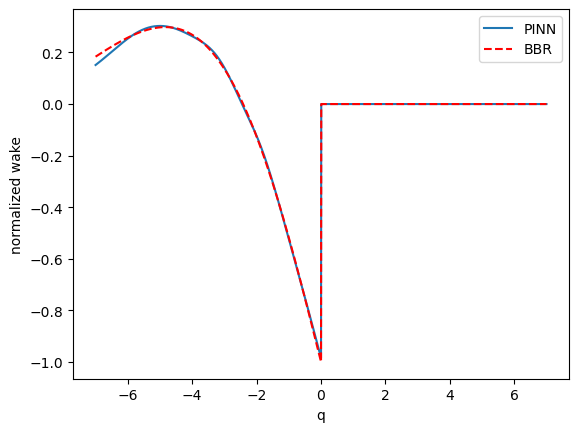

In [32]:
u_pred = model(x_test).cpu().detach().numpy()
x0 = x_test.cpu().detach().numpy()

plt.plot(x0,u_pred,label='PINN')

plt.xlabel('q')
plt.ylabel('normalized wake')

RW_Y=bbr(x0,0.5)
RW_Y[x0>0]=0
plt.plot(x0,RW_Y,linestyle='dashed',label='BBR',c='r')

#plt.xlim(-7,7)
#plt.ylim(-5,1)
plt.legend()

In [33]:
np.sum(np.abs((RW_Y[571:1000]-u_pred[571:1000])))/np.sum(np.abs(RW_Y[571:1000]))

np.float64(0.01354085944313266)